# Single Contact Discontinuity 

## Importing Libraries

In [150]:
import pandas as pd  # Pandas
import numpy as np # Numpy
import matplotlib.pyplot as plt # Pyplot as plt ploting in matplotlib
from matplotlib import cm # for Ploting 

import math # Math
import time # Time

from pyDOE import lhs

# Import torch libraries
import torch
from torch import Tensor
import torch.autograd as autograd
import torch.optim as optim
import torch.nn as nn

# Libraries for saving datafiles
from numpy import asarray
from numpy import savetxt

## Set seed values for Random number generation

In [151]:
## Random seed values:
torch.set_default_dtype(torch.float)
torch.manual_seed(789)
np.random.seed(789)

## Check GPU

In [152]:
torch.cuda.empty_cache() # Empty the cache memory
device=torch.cuda.get_device_name() # Save the device name of gpu

print("- Original device name:",device)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("- Now device name is :- ",device)

- Original device name: NVIDIA GeForce RTX 3060 Laptop GPU
- Now device name is :-  cuda


## Generating data set for training the Model

In [153]:
x_data=np.linspace(0,1,100)[:,None] # Generate data x (position) from 0 to 1
t_data=np.linspace(0,2,100)[:,None] # Generate data t (time) for 0 to 2 s

In [154]:
# Generating mesh of the xt data
X,T=np.meshgrid(x_data,t_data)

# Flatten the grid structure to a matrix of size [100*100 X 2]
xt_train=np.hstack((X.flatten()[:,None],T.flatten()[:,None]))

In [155]:
# Convert thedata to torch and take it to device(gpu)
XT_Test=torch.from_numpy(xt_train).float().to(device)

## Initial Condition

In [156]:
Initial_xt=xt_train[0:100,:] # Initial values
#print(Initial_xt)

# Left values from x* 
Initial_xt_left=Initial_xt[:50,:]

# right values from x*
Initial_xt_right=Initial_xt[50:,:]

# Initial condition at left of discontinuity (x*)
Initial_left_Rho=[1.4]*(len(Initial_xt_left))
Initial_left_u=[0.1]*(len(Initial_xt_left))
Initial_left_P=[1]*(len(Initial_xt_left))

# Initial condition at right of discontinuity (x*)
Initial_right_Rho=[1]*(len(Initial_xt_right))
Initial_right_u=[0.1]*(len(Initial_xt_right))
Initial_right_P=[1]*(len(Initial_xt_right))

# Converting the values to the array
Initial_xt_left=np.array(Initial_xt_left)
Initial_xt_right=np.array(Initial_xt_right)

Initial_left_Rho=np.array(Initial_left_Rho)[:,None]
Initial_left_u=np.array(Initial_left_u)[:,None]
Initial_left_P=np.array(Initial_left_P)[:,None]

Initial_right_Rho=np.array(Initial_right_Rho)[:,None]
Initial_right_u=np.array(Initial_right_u)[:,None]
Initial_right_P=np.array(Initial_right_P)[:,None]

#print(Initial_xt_left)

## Boundary Condition

In [157]:
# Boundary values at the lest boundary
Boundary_left=[xt_train[i,:] for i in range(len(xt_train)) if xt_train[i,0]==0]
Boundary_left=np.array(Boundary_left)

# Boundary values at the right boundary
Boundary_right=[xt_train[i,:] for i in range(len(xt_train)) if xt_train[i,0]==1]
Boundary_right=np.array(Boundary_right)

# Boundary conditions at left side
Boundary_left_Rho=[1.4]*(len(Boundary_left))
Boundary_left_u=[0.1]*(len(Boundary_left))
Boundary_left_P=[1]*(len(Boundary_left))

# Boundary conditions at right side
Boundary_right_Rho=[1]*(len(Boundary_right))
Boundary_right_u=[0.1]*(len(Boundary_right))
Boundary_right_P=[1]*(len(Boundary_right))

# Converting the values to array
Boundary_left_Rho=np.array(Boundary_left_Rho)[:,None]
Boundary_left_u=np.array(Boundary_left_u)[:,None]
Boundary_left_P=np.array(Boundary_left_P)[:,None]
Boundary_right_Rho=np.array(Boundary_right_Rho)[:,None]
Boundary_right_u=np.array(Boundary_right_u)[:,None]
Boundary_right_P=np.array(Boundary_right_P)[:,None]


## Stacking the Values

In [158]:
# Stacking the values of initial and values
Initial_condition=np.vstack((Initial_xt_left,Initial_xt_right))
Initial_condition_Rho=np.vstack((Initial_left_Rho,Initial_right_Rho))
Initial_condition_U=np.vstack((Initial_left_u,Initial_right_u))
Initial_condition_P=np.vstack((Initial_left_P,Initial_right_P))

#plt.plot(Initial_condition[:,0],Initial_condition_Rho)

Boundary_condition=np.vstack((Boundary_left,Boundary_right))
Boundary_condition_Rho=np.vstack((Boundary_left_Rho,Boundary_right_Rho))
Boundary_condition_U=np.vstack((Boundary_left_u,Boundary_right_u))
Boundary_condition_P=np.vstack((Boundary_left_P,Boundary_right_P))

# Stacking the values horizontaly as: [Rho, U, P]
Initial_condition_Rho_U_P=np.hstack((Initial_condition_Rho,Initial_condition_U,Initial_condition_P))
Boundary_condition_Rho_U_P=np.hstack((Boundary_condition_Rho,Boundary_condition_U,Boundary_condition_P))

#print(Initial_condition)
#print(Boundary_condition)

In [159]:
# Stacking the values virtually Initial and boundary as: [Initial,
                                                        # Boundary]
X_train=np.vstack((Initial_condition,Boundary_condition))

# Stacking the values virtually Initial and boundary as: [Initial_RHO_U_P,
                                                        # Boundary_RHO_U_P]

U_train=np.vstack((Initial_condition_Rho_U_P,Boundary_condition_Rho_U_P))
#print(X_train)

## Upper and Lower Limit for Feature scaling


In [160]:
lb=xt_train[0] # lower limit
ub=xt_train[-1] # Upper limit

## Generate Training Data

In [161]:
Nu=200 # Number of training points
Nf=500 # Number of residual points

XT_f_train=lb+(ub-lb)*lhs(2,Nf)

#plt.scatter(XT_f_train[:,0],XT_f_train[:,1])
#plt.scatter(X_train[:,0],X_train[:,1])

In [162]:
idx=np.random.choice(X_train.shape[0],Nu,replace=False)
#print(idx.shape)
XT_train=X_train[idx,:]
U_train=U_train[idx,:]


In [163]:
# Save data for the epochs. Random data generated inside the domain.

#savetxt('XT_f_train',XT_f_train,delimiter=',')
#savetxt('XT_train',XT_train,delimiter=',')

## Convert the float to Torch 

In [164]:
XT_train=torch.from_numpy(XT_train).float().to(device)
U_train=torch.from_numpy(U_train).float().to(device)

XT_f_train=torch.from_numpy(XT_f_train).float().to(device)
f_hat=torch.zeros(XT_f_train.shape[0],1).to(device)

In [165]:
print(XT_train.shape)
print(U_train.shape)
print(XT_f_train.shape)

torch.Size([200, 2])
torch.Size([200, 3])
torch.Size([500, 2])


## PINNs

In [166]:
class Single_Discontinuity(nn.Module):
    
    def __init__(self,layers):
        
        # Inherentance: taking the function from nn.module
        super().__init__()
        
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the Loss function as Mean square Loss function
        self.Loss_function=nn.MSELoss(reduction='mean')
        
        # Generating the ModuleList
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1]) for i in range(len(layers)-1)])
        
        # Iteration
        self.iter=0
        
        # Defining the Xavier normal for weight and zero as bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=5/3)
            nn.init.zeros_(self.linears[i].bias.data)
    
    # Forward Pass function
    def forward(self,X):
        
        # Check whether the X data is Tensor or not
        if torch.is_tensor(X)!=True:
            X=torch.from_numpy(X)
            
        # Converting the Boundary values (min,max)
        L_b=torch.from_numpy(lb).float().to(device)
        U_b=torch.from_numpy(ub).float().to(device)
        
        # Feature Scale
        X=(X-L_b)/(U_b-L_b)
        
        a=X.float()
        
        Rho_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        U_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        P_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        
        # Forward Pass loop upto the second last layer 
        for i in range(len(layers)-2):
            z1=self.linears[i](Rho_Pred)
            z2=self.linears[i](U_Pred)
            z3=self.linears[i](P_Pred)
            
            Rho_Pred=self.activation(z1)
            U_Pred=self.activation(z2)
            P_Pred=self.activation(z3)
            
        # Pass the the data to the last layer
        Rho_Pred=self.linears[-1](Rho_Pred)
        U_Pred=self.linears[-1](U_Pred)
        P_Pred=self.linears[-1](P_Pred)
        
        # a=[Rho, U, P]
        a=torch.cat((Rho_Pred,U_Pred,P_Pred),1)
        
        return a
    
    def LossBC(self,X,Y):
        
        # Forward Pass the X data for boundary and Initial Values
        Pred_val=self.forward(X)
        
        PRED_RHO=Pred_val[:,[0]]
        PRED_U=Pred_val[:,[1]]
        PRED_P=Pred_val[:,[2]]
        
        # Calculating the MSE Loss of predicted data
        Loss_Rho=self.Loss_function(PRED_RHO,Y[:,[0]])
        
        Loss_U=self.Loss_function(PRED_U,Y[:,[1]])
        Loss_P=self.Loss_function(PRED_P,Y[:,[2]])
        
        # total Boundary and Initial Loss
        Loss_BC=Loss_Rho+Loss_U+Loss_P
        
        return Loss_BC
    
    def LossPDE(self,xy_to_train_f):
        
        # Gamma for air
        gamma=1.4
        
        g=xy_to_train_f.clone()
        
        g.requires_grad=True
        
        # Forward Pass the the data xy_to_train_f
        RHO_U_P=self.forward(g)
        
        RHO=RHO_U_P[:,[0]]
        U=RHO_U_P[:,[1]]
        P=RHO_U_P[:,[2]]
        
        # Calculating the gradient of the calculated RHO
        RHO_xt=autograd.grad(RHO,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        RHO_x=RHO_xt[:,[0]]
        RHO_t=RHO_xt[:,[1]]
        
        # Calculating the gradient of the calculated U
        U_xt=autograd.grad(U,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        U_x=U_xt[:,[0]]
        U_t=U_xt[:,[1]]
        
        # Calculating the gradient of the calculated P
        P_xt=autograd.grad(P,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        P_x=P_xt[:,[0]]
        P_t=P_xt[:,[1]]
        
        # Three eqution, Conservation of mass, momentum and energy
        F1=RHO_t + U*(RHO_x) + RHO*(U_x)
        F2=RHO*(U_t + U*(U_x)) + P_x
        F3=P_t + gamma*P*(U_x) + U*(P_x)
        # Equation 
        # 1,2,3
        
        # MSE Loss function Calculation 
        LossF1=self.Loss_function(F1,f_hat)
        LossF2=self.Loss_function(F2,f_hat)
        LossF3=self.Loss_function(F3,f_hat)
        
        # Total PDE LOSS
        LossPDE=LossF1+LossF2+LossF3
        
        return LossPDE
    
    def Loss(self,X,Y,xy_to_train_f):
        
        # Calling the Boundary Loss function
        Loss1=self.LossBC(X,Y)
        
        # Calling the PDE Loss function
        Loss2=self.LossPDE(xy_to_train_f)
        
        # Total MSE LOSS--> Sum of the PDE_LOSS + BC_LOSS
        Total_Loss=Loss1 + Loss2   # Dynamic Weights
        
        #total_loss=Loss1+Loss2
        
        # Saving the Data
        #file1=open('BC_LOSS.txt','a')
        #file1.write(str(Loss1.item())+'\n')
        #file1.close()
        
        #file1=open('PDE_LOSS.txt','a')
        #file1.write(str(Loss2.item())+'\n')
        #file1.close()
        
        #file3=open('TOTAL_LOSS_W.txt','a')
        #file3.write(str(Total_Loss.item())+'\n')
        #file3.close()
        
        #file4=open('TOTAL_LOSS.txt','a')
        #file4.write(str(total_loss.item())+'\n')
        #file4.close()
        
        return Total_Loss
    
    def closure(self):
        
        # Initial taking the gradient as zero
        optimizer.zero_grad()
        
        # Calling the Loss function
        Loss=self.Loss(XT_train,U_train,XT_f_train)
        
        # Backprop
        Loss.backward()
        
        # Iteration +=1
        self.iter+=1
        
        # Print the Loss at every 100 iteration
        if self.iter%100==0:
            print(Loss)
            
        return Loss
    
    def Test(self,Test_data):
        
        # Forward Pass the Test Data
        Result_Pred=self.forward(Test_data)
        
        # Taking the Results to the cpu from the gpu
        Result_Pred=Result_Pred.detach().cpu().numpy()
        
        Density_Pred=Result_Pred[:,[0]]
        Velocity_Pred=Result_Pred[:,[1]]
        Pressure_Pred=Result_Pred[:,[2]]
        
        # Predict the dependent parameters=[Density,Velocity,Pressure]
        return [Density_Pred,Velocity_Pred,Pressure_Pred]
        

In [167]:
layers=[2,40,40,3] # No of neurons with each layer

SD=Single_Discontinuity(layers) # Object of the class
SD.to(device) # Passing the object to the device

params=list(SD.parameters())

# We can use multiple optimization by number of ways:
#                                           1. Adam + LBFGS
#                                           2. LBFGS + LBFGS (with different learning rate and other parameters)

# Optimization methods (here we have used only 1 optimization)
optimizer=optim.LBFGS(SD.parameters(),lr=0.1,max_iter=10000)

# Training time for the optimization
start_time1=time.time()
optimizer.step(SD.closure)
Training_time1=time.time()-start_time1

print("Training Time:-",Training_time1)

tensor(0.0043, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0025, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0020, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0018, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0016, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0016, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0015, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0013, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0009, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0008, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0006, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0006, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0005, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0004, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0004, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0004, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0003, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0003, device='cuda:0', grad_fn=<AddBack

---
---

## Prediction 

- ###  At time t=0

In [168]:
Test_data1=XT_Test[0:100,:]
print(Test_data1[-1])
[RHO_PRED_t0,U_PRED_t0,P_PRED_t0]=SD.Test(Test_data1)

tensor([1., 0.], device='cuda:0')


In [169]:
Test_data1=Test_data1.detach().cpu().numpy()

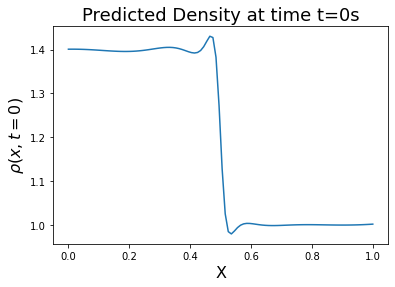

In [170]:
plt.plot(Test_data1[:,[0]],RHO_PRED_t0)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$\rho(x,t=0)$", fontsize=16)
plt.title("Predicted Density at time t=0s",fontsize=18)
plt.show()
#savetxt('X_plot_t0',Test_data1[:,[0]],delimiter=',')
#savetxt('RHO_PRED_t0',RHO_PRED_t0,delimiter=',')

##------------##----------------##-------------##------------##

#plt.plot(Test_data1[:,[0]],U_PRED_t0)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"U(x,t=0)", fontsize=16)
#plt.title("Predicted Velocity at time t=0s",fontsize=18)
#plt.show()
#savetxt('X_plot_t0',Test_data1[:,[0]],delimiter=',')
#savetxt('U_PRED_t0',U_PRED_t0,delimiter=',')

##------------##----------------##-------------##------------##

#plt.plot(Test_data1[:,[0]],P_PRED_t0)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"P(x,t=0)", fontsize=16)
#plt.title("Predicted Presssure at time t=0s",fontsize=18)
#plt.show()
#savetxt('X_plot_t0',Test_data1[:,[0]],delimiter=',')
#savetxt('P_PRED_t0',P_PRED_t0,delimiter=',')

- ### t=0.5

In [171]:
Test_data05=XT_Test[2500:2600,:]
print(Test_data05[-1])
[RHO_PRED_t05,U_PRED_t05,P_PRED_t05]=SD.Test(Test_data05)

tensor([1.0000, 0.5051], device='cuda:0')


In [172]:
Test_data05=Test_data05.detach().cpu().numpy()

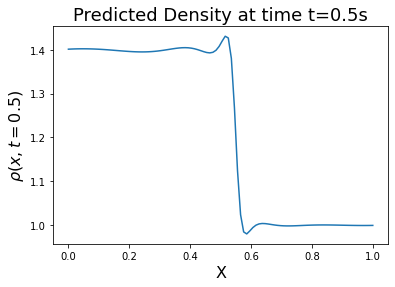

In [173]:
plt.plot(Test_data05[:,[0]],RHO_PRED_t05)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$\rho(x,t=0.5)$", fontsize=16)
plt.title("Predicted Density at time t=0.5s",fontsize=18)
plt.show()

#savetxt('X_plot_t05',Test_data05[:,[0]],delimiter=',')
#savetxt('RHO_PRED_t05',RHO_PRED_t05,delimiter=',')

##-----------##----------##------------##----------------##

#plt.plot(Test_data05[:,[0]],U_PRED_t05)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"U(x,t=0.5)", fontsize=16)
#plt.title("Predicted Velocity at time t=0.5s",fontsize=18)
#plt.show()
#savetxt('X_plot_t05',Test_data05[:,[0]],delimiter=',')
#savetxt('U_PRED_t05',U_PRED_t05,delimiter=',')

##----------------##----------------##-----------------##------------##

#plt.plot(Test_data05[:,[0]],P_PRED_t05)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"P(x,t=0.5)", fontsize=16)
#plt.title("Predicted Pressure at time t=0.5s",fontsize=18)
#plt.show()
#savetxt('X_plot_t05',Test_data05[:,[0]],delimiter=',')
#savetxt('P_PRED_t05',P_PRED_t05,delimiter=',')

- ### t=1

In [174]:
Test_data1=XT_Test[5000:5100,:]
print(Test_data1[-1])
[RHO_PRED_t1,U_PRED_t1,P_PRED_t1]=SD.Test(Test_data1)

tensor([1.0000, 1.0101], device='cuda:0')


In [175]:
Test_data1=Test_data1.detach().cpu().numpy()

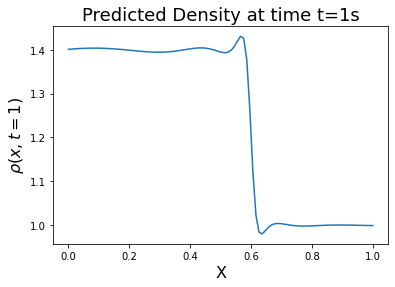

In [176]:
plt.plot(Test_data1[:,[0]],RHO_PRED_t1)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$\rho(x,t=1)$", fontsize=16)
plt.title("Predicted Density at time t=1s",fontsize=18)
plt.show()
#savetxt('X_plot_t1',Test_data1[:,[0]],delimiter=',')
#savetxt('RHO_PRED_t1',RHO_PRED_t1,delimiter=',')

##-----------##----------##------------##----------------##

#plt.plot(Test_data1[:,[0]],U_PRED_t1)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"U(x,t=1)", fontsize=16)
#plt.title("Predicted Velocity at time t=1s",fontsize=18)
#plt.show()
#savetxt('X_plot_t1',Test_data1[:,[0]],delimiter=',')
#savetxt('U_PRED_t1',U_PRED_t1,delimiter=',')

##----------------##----------------##-----------------##------------##

#plt.plot(Test_data1[:,[0]],P_PRED_t1)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"P(x,t=1)", fontsize=16)
#plt.title("Predicted Pressure at time t=1s",fontsize=18)
#plt.show()
#savetxt('X_plot_t1',Test_data1[:,[0]],delimiter=',')
#savetxt('P_PRED_t1',P_PRED_t1,delimiter=',')

- ### t=2

In [177]:
Test_data2=XT_Test[9900:,:]
print(Test_data2[-1])
[RHO_PRED_t2,U_PRED_t2,P_PRED_t2]=SD.Test(Test_data2)

tensor([1., 2.], device='cuda:0')


In [178]:
Test_data2=Test_data2.detach().cpu().numpy()

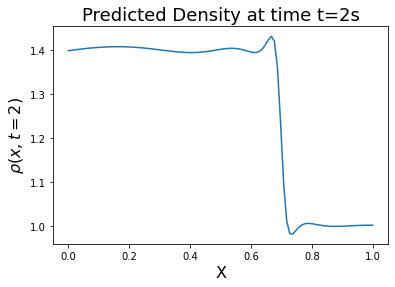

In [179]:
plt.plot(Test_data2[:,[0]],RHO_PRED_t2)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$\rho(x,t=2)$", fontsize=16)
plt.title("Predicted Density at time t=2s",fontsize=18)
plt.show()
#savetxt('X_plot_t2',Test_data2[:,[0]],delimiter=',')
#savetxt('RHO_PRED_t2',RHO_PRED_t2,delimiter=',')

##-----------##----------##------------##----------------##

#plt.plot(Test_data2[:,[0]],U_PRED_t2)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"U(x,t=2)", fontsize=16)
#plt.title("Predicted Velocity at time t=2s",fontsize=18)
#plt.show()
#savetxt('X_plot_t2',Test_data2[:,[0]],delimiter=',')
#savetxt('U_PRED_t2',U_PRED_t2,delimiter=',')

##----------------##----------------##-----------------##------------##

#plt.plot(Test_data2[:,[0]],P_PRED_t2)
#plt.xlabel("X",fontsize=16)
#plt.ylabel(r"P(x,t=2)", fontsize=16)
#plt.title("Predicted Pressure at time t=2s",fontsize=18)
#plt.show()
#savetxt('X_plot_t2',Test_data2[:,[0]],delimiter=',')
#savetxt('P_PRED_t2',P_PRED_t2,delimiter=',')

---
---

## Save Data for Ploting

In [180]:
# Predicting the result for the all data set

Result=XT_Test

#print(Test_data1[-1])

# Predicting the result
[RHO_PRED_t0,U_PRED_t0,P_PRED_t0]=SD.Test(Result)

In [181]:
# Taking the data to the cpu
XT_Test=XT_Test.detach().cpu().numpy()
Result=Result.detach().cpu().numpy()

In [182]:
# Reshaping the data
RHO_PRED_MESH=np.reshape(RHO_PRED_t0,(100,100),order='F')
U_PRED_MESH=np.reshape(U_PRED_t0,(100,100),order='F')
P_PRED_MESH=np.reshape(P_PRED_t0,(100,100),order='F')

#print(RHO_PRED_MESH.shape)
#print(Result.shape)

# Reshaping the x and t axis data
XPLOT=np.reshape(Result[:,[0]],(100,100),order='F')
print(XPLOT.shape)

TPLOT=np.reshape(Result[:,[1]],(100,100),order='F')
print(TPLOT.shape)

(100, 100)
(100, 100)


In [183]:
# Saving the data

#savetxt('RHO_PRED_MESH',RHO_PRED_MESH,delimiter=',')
#savetxt('U_PRED_MESH',U_PRED_MESH,delimiter=',')
#savetxt('P_PRED_MESH',P_PRED_MESH,delimiter=',')


#savetxt('XPLOT',XPLOT,delimiter=',')
#savetxt("TPLOT",TPLOT,delimiter=',')

---
---

## Exact Solution

In [184]:
## Exact solution at t=0s

Exact_t0=xt_train[0:100,:]
#print(Initial_xt)
Exact_xt0_left=Exact_t0[:50,:]
Exact_xt0_right=Exact_t0[50:,:]
Exact_t0_left_Rho=[1.4]*(len(Exact_xt0_left))
Exact_t0_right_Rho=[1]*(len(Exact_xt0_right))
RHO_LEFT_t0=np.hstack((Exact_t0_left_Rho,Exact_t0_right_Rho))

print(RHO_LEFT_t0.shape)
#################################################################

## Exact solution at t=1s

Exact_t1=xt_train[5000:5100,:]
#print(Exact_t1)
Exact_xt1_left=Exact_t1[:61,:]
Exact_xt1_right=Exact_t1[62:,:]
Exact_t1_left_Rho=[1.4]*(len(Exact_xt1_left))
Exact_t1_right_Rho=[1]*(len(Exact_xt1_right))
#print(Exact_xt1_left)
RHO_LEFT_t1=np.hstack((Exact_t1_left_Rho,Exact_t1_right_Rho))

##################################################################

## Exact solution at t=2s

Exact_t2=(xt_train[9900:,:])
#print(Exact_t2)
Exact_xt2_left=Exact_t2[:71,:]
Exact_xt2_right=Exact_t2[71:,:]
#print(Exact_xt2_right)
Exact_t2_left_Rho=[1.4]*(len(Exact_xt2_left))
Exact_t2_right_Rho=[1]*(len(Exact_xt2_right))
RHO_LEFT_t2=np.hstack((Exact_t2_left_Rho,Exact_t2_right_Rho))
print(RHO_LEFT_t2.shape)
#savetxt('Exact_t1',Exact_t1,delimiter=',')
#savetxt('RHO_LEFT_t1',RHO_LEFT_t1,delimiter=',')


Exact_t2_left_u=[0.1]*(len(Exact_xt2_left))
Exact_t2_right_u=[0.1]*(len(Exact_xt2_right))
U_LEFT_t2=np.hstack((Exact_t2_left_u,Exact_t2_right_u))

Exact_t2_left_p=[1]*(len(Exact_xt2_left))
Exact_t2_right_p=[1]*(len(Exact_xt2_right))
P_LEFT_t2=np.hstack((Exact_t2_left_p,Exact_t2_right_p))

(100,)
(100,)


## Relative Error

$$\frac{||\rho_{Exact}-\rho_{Predicted}||_{L2}}{||\rho_{Exact}||_{L2}}$$

In [185]:
# Relative error for density

error=0
sum_pred=0
for i in range(len(RHO_LEFT_t2)):
    error+=((RHO_LEFT_t2[i]-RHO_PRED_t2[i])**2)
    sum_pred+=(RHO_LEFT_t2[i])**2


error_root=error**0.5/(sum_pred**0.5)
print("\n The Relative Error for density: ",error_root[-1])


 The Relative Error for density:  0.027248494


In [186]:
# Relative error for velocity

error=0
sum_pred=0
for i in range(len(U_LEFT_t2)):
    error+=((U_LEFT_t2[i]-(U_PRED_t2[i]))**2)
    sum_pred+=(U_LEFT_t2[i])**2


error_root=error**0.5/(sum_pred**0.5)
print("\n The Relative Error for velocity: ",error_root[-1])


 The Relative Error for velocity:  0.0027911803


In [187]:
# Relative error for pressure

error=0
sum_pred=0
for i in range(len(P_LEFT_t2)):
    error+=((P_LEFT_t2[i]-(P_PRED_t2[i]))**2)
    sum_pred+=(P_LEFT_t2[i])**2


error_root=error**0.5/(sum_pred**0.5)
print("\n The Relative Error for pressure: ",error_root[-1])


 The Relative Error for pressure:  0.00053860823


---
---